# Actividad grupal clase 2 — Modelos con ecuaciones diferenciales

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Integrantes del grupo:** _(listar aquí a los integrantes)_

Contenido:
0. Organización
1. Miniexploración a mano: ley de enfriamiento de Newton
2. El modelo logístico en código (`solve_ivp` vs. solución analítica)
3. El modelo SIR con tres escenarios de $R_0$
4. Ajuste del logístico a la población de Costa Rica
5. Reflexión grupal

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit

---
## Parte 1: Miniexploración a mano — ley de enfriamiento de Newton

$$\frac{dT}{dt}=-k\,(T-T_{\text{amb}}),\qquad k>0,\quad T(0)=T_0$$

### 1.1 Clasificación de la EDO

- **Orden 1:** solo aparece la primera derivada $dT/dt$.
- **Lineal:** se puede escribir $T' + kT = kT_{\text{amb}}$, que es lineal en $T$ y en $T'$ (no hay productos ni potencias de $T$). Es lineal **no homogénea** de coeficientes constantes.
- **Autónoma:** el lado derecho depende solo de $T$, no de $t$ de forma explícita.

### 1.2 La ecuación en una frase

La rapidez con la que cambia la temperatura es **proporcional a la diferencia** entre la temperatura del objeto y la del ambiente: cuanto más lejos está del ambiente, más rápido se enfría (o calienta), y conforme se acerca el cambio se hace cada vez más lento. El signo menos hace que la diferencia siempre se achique.

### 1.3 Equilibrio

$$\frac{dT}{dt}=0\iff -k(T^*-T_{\text{amb}})=0\iff T^*=T_{\text{amb}}.$$

Físicamente: el objeto deja de cambiar cuando llega a la **temperatura del ambiente** (equilibrio térmico).

### 1.4 Diagrama de fase y estabilidad

- Si $T>T_{\text{amb}}$: $dT/dt<0$, la temperatura **baja** (flecha hacia la izquierda).
- Si $T<T_{\text{amb}}$: $dT/dt>0$, la temperatura **sube** (flecha hacia la derecha).

En ambos casos las flechas apuntan hacia $T_{\text{amb}}$, así que el equilibrio es **estable** (atractor). Formalmente, $f'(T^*)=-k<0$, lo que confirma la estabilidad.

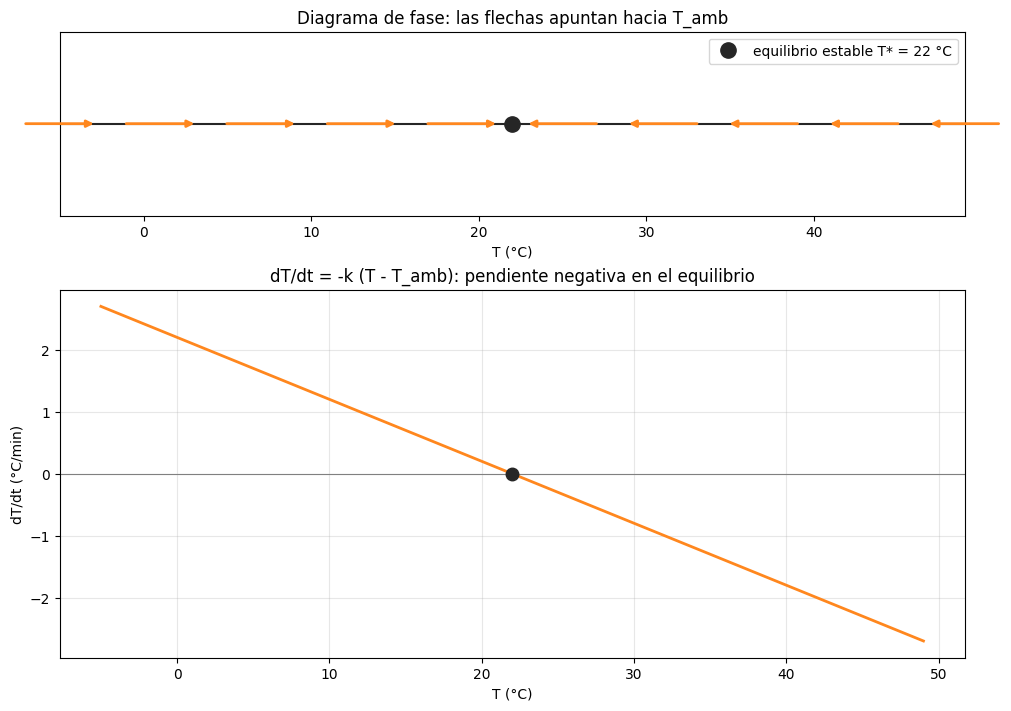

In [2]:
# Diagrama de fase sobre la recta T, con k = 0.1 y T_amb = 22 °C
k, T_amb = 0.1, 22.0
f = lambda T: -k * (T - T_amb)               # campo vectorial dT/dt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), layout="constrained",
                               gridspec_kw={"height_ratios": [1, 2]})

# (a) recta de fase: flechas según el signo de dT/dt
ax1.axhline(0, color="#262626", lw=1.5)
for T in np.linspace(-5, 49, 10):
    if abs(T - T_amb) < 1: continue
    d = np.sign(f(T)) * 2.2
    ax1.annotate("", xy=(T + d, 0), xytext=(T - d, 0),
                 arrowprops=dict(arrowstyle="-|>", color="#FF871E", lw=2))
ax1.plot(T_amb, 0, "o", ms=11, color="#262626", label=f"equilibrio estable T* = {T_amb:.0f} °C")
ax1.set(yticks=[], ylim=(-1, 1), xlim=(-5, 49), xlabel="T (°C)", title="Diagrama de fase: las flechas apuntan hacia T_amb")
ax1.legend(loc="upper right")

# (b) gráfico de f(T) contra T
T = np.linspace(-5, 49, 200)
ax2.plot(T, f(T), color="#FF871E", lw=2)
ax2.axhline(0, color="gray", lw=0.8)
ax2.plot(T_amb, 0, "o", ms=9, color="#262626")
ax2.set(xlabel="T (°C)", ylabel="dT/dt (°C/min)", title="dT/dt = -k (T - T_amb): pendiente negativa en el equilibrio")
ax2.grid(alpha=0.3)
plt.show()

### 1.5 Bosquejo de $T(t)$: café a 85 °C y refresco a 5 °C en un cuarto a 22 °C

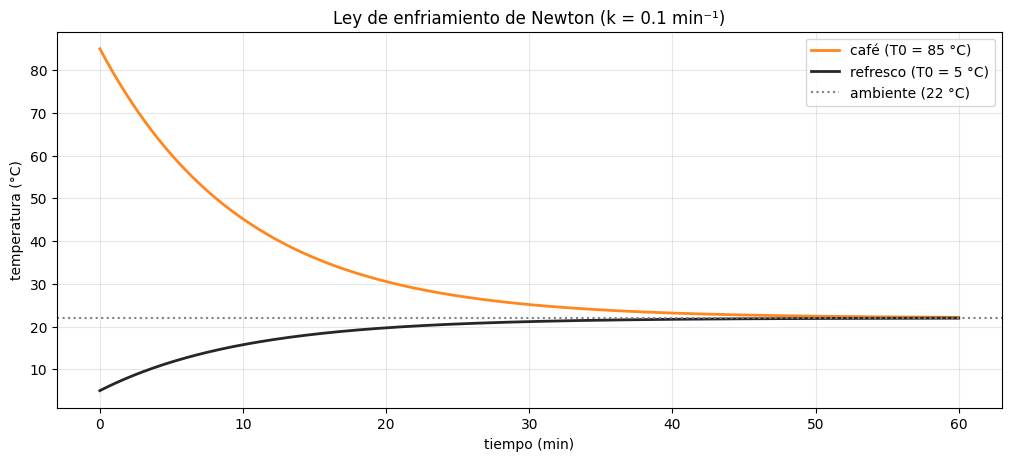

In [3]:
# Solución analítica T(t) = T_amb + (T0 - T_amb) e^{-kt}  (se deduce en 1.6)
t = np.linspace(0, 60, 400)
T_cafe = T_amb + (85 - T_amb) * np.exp(-k * t)
T_refresco = T_amb + (5 - T_amb) * np.exp(-k * t)

fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
ax.plot(t, T_cafe, color="#FF871E", lw=2, label="café (T0 = 85 °C)")
ax.plot(t, T_refresco, color="#262626", lw=2, label="refresco (T0 = 5 °C)")
ax.axhline(T_amb, color="gray", ls=":", label="ambiente (22 °C)")
ax.set(xlabel="tiempo (min)", ylabel="temperatura (°C)", title="Ley de enfriamiento de Newton (k = 0.1 min⁻¹)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

**¿Qué tienen en común las dos curvas?** Las dos son exponenciales que se acercan **monótonamente y de forma asintótica** a 22 °C, sin cruzarla nunca: el café baja y el refresco sube. Ambas cambian más rápido al principio (cuando la diferencia con el ambiente es grande) y más lento al final, y comparten la misma constante de tiempo $1/k=10$ min: la diferencia con el ambiente se reduce en un factor $e$ cada 10 min. Una es el reflejo de la otra respecto de la recta $T=T_{\text{amb}}$.

### 1.6 (Opcional) Solución por separación de variables

$$\frac{dT}{T-T_{\text{amb}}}=-k\,dt\;\Rightarrow\;\ln|T-T_{\text{amb}}|=-kt+C\;\Rightarrow\;T(t)=T_{\text{amb}}+(T_0-T_{\text{amb}})\,e^{-kt}.$$

Con $T_0=85$, $T_{\text{amb}}=22$, $k=0.1$ y $T(t)=40$:

$$40=22+63\,e^{-0.1t}\;\Rightarrow\;e^{-0.1t}=\frac{18}{63}\;\Rightarrow\;t=10\,\ln\!\frac{63}{18}=10\ln 3.5\approx \mathbf{12.5\ \text{min}}.$$

In [4]:
# Verificación numérica de 1.6
t_40 = np.log((85 - T_amb) / (40 - T_amb)) / k
print(f"el café llega a 40 °C en {t_40:.2f} min")

# y comprobación con solve_ivp (evento: cruzar 40 °C)
cruce = lambda t, T: T[0] - 40
cruce.terminal = True
sol = solve_ivp(lambda t, T: -k * (T - T_amb), (0, 60), [85], events=cruce, rtol=1e-9)
print(f"solve_ivp (evento)         -> {sol.t_events[0][0]:.2f} min")

el café llega a 40 °C en 12.53 min
solve_ivp (evento)         -> 12.53 min


---
## Parte 2: El modelo logístico en código

$$\frac{dN}{dt}=rN\left(1-\frac{N}{K}\right),\qquad N(t)=\frac{K}{1+\frac{K-N_0}{N_0}e^{-rt}}$$

Es un ejercicio de **validación**: si la curva numérica (RK45) y la analítica coinciden, ambos métodos funcionan.

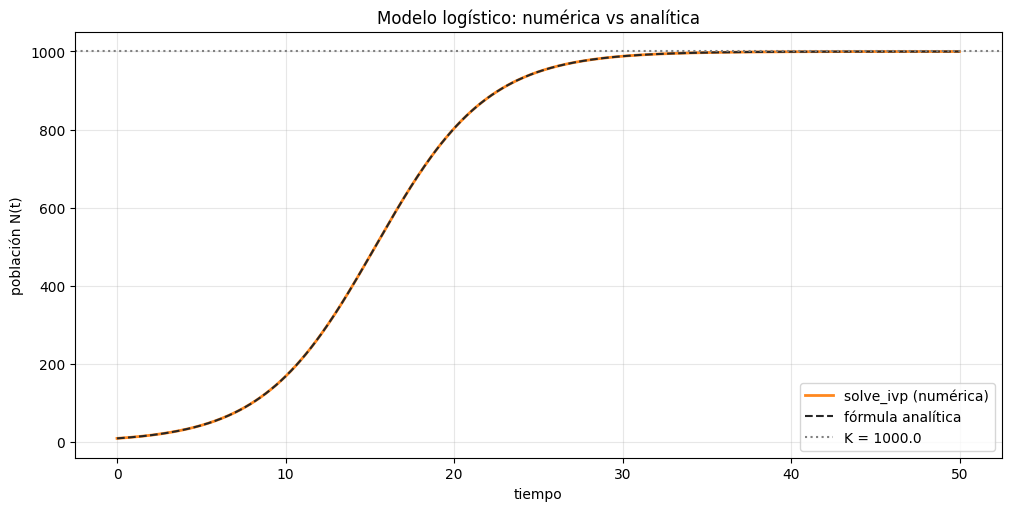

diferencia máxima entre ambas curvas: 3.20e-05 individuos


In [5]:
# Parámetros del modelo
r = 0.3          # tasa intrínseca de crecimiento
K = 1000.0       # capacidad de carga
N0 = 10.0        # población inicial

# 1. Solución numérica con solve_ivp (RK45)
def logistico(t, N):
    return r * N * (1 - N / K)

t_eval = np.linspace(0, 50, 500)
sol = solve_ivp(logistico, t_span=(0, 50), y0=[N0],
                t_eval=t_eval, method='RK45', rtol=1e-8)

# 2. Solución analítica (la fórmula de la pizarra)
def analitica(t, K, r, N0):
    return K / (1 + ((K - N0) / N0) * np.exp(-r * t))

# 3. Comparación
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
ax.plot(sol.t, sol.y[0], label='solve_ivp (numérica)', color='#FF871E', lw=2)
ax.plot(t_eval, analitica(t_eval, K, r, N0), label='fórmula analítica',
        color='#262626', lw=1.5, linestyle='--')
ax.axhline(K, color='gray', linestyle=':', label=f'K = {K}')
ax.set_xlabel('tiempo'); ax.set_ylabel('población N(t)')
ax.set_title('Modelo logístico: numérica vs analítica')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

dif = np.max(np.abs(sol.y[0] - analitica(t_eval, K, r, N0)))
print(f"diferencia máxima entre ambas curvas: {dif:.2e} individuos")

**Verificación:** la diferencia máxima es del orden de $10^{-5}$ individuos sobre una población de 1000, es decir, imperceptible: las dos curvas coinciden. La curva es una sigmoide (forma de S): crece casi exponencialmente al principio (cuando $N\ll K$), tiene su mayor pendiente en $N=K/2$ y se aplana al acercarse a $K$.

### Pregunta para discutir: ¿qué pasa si $N_0>K$ (por ejemplo $N_0=1500$)?

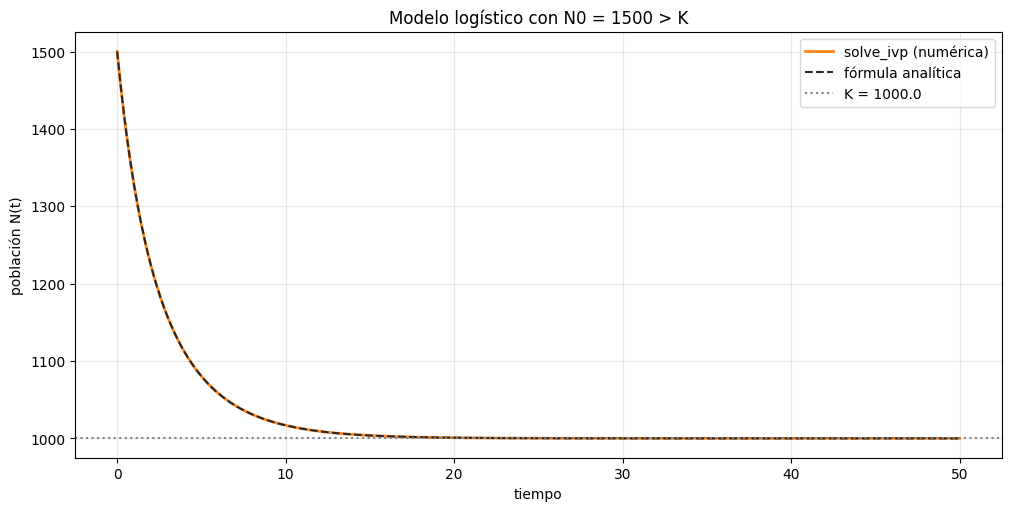

dif. máxima: 5.13e-06 | N(0) = 1500.0 | N(50) = 1000.0


In [6]:
N0_alto = 1500.0
sol_alto = solve_ivp(logistico, (0, 50), [N0_alto], t_eval=t_eval, method='RK45', rtol=1e-8)

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
ax.plot(sol_alto.t, sol_alto.y[0], label='solve_ivp (numérica)', color='#FF871E', lw=2)
ax.plot(t_eval, analitica(t_eval, K, r, N0_alto), label='fórmula analítica',
        color='#262626', lw=1.5, linestyle='--')
ax.axhline(K, color='gray', linestyle=':', label=f'K = {K}')
ax.set_xlabel('tiempo'); ax.set_ylabel('población N(t)')
ax.set_title('Modelo logístico con N0 = 1500 > K')
ax.legend(); ax.grid(alpha=0.3)
plt.show()
print("dif. máxima:", f"{np.max(np.abs(sol_alto.y[0] - analitica(t_eval, K, r, N0_alto))):.2e}",
      "| N(0) =", sol_alto.y[0][0], "| N(50) =", round(sol_alto.y[0][-1], 3))

**Explicación.** La curva **decrece** desde 1500 y se acerca a $K=1000$ por arriba, sin cruzarla (decaimiento monótono, sin forma de S). Coincide con lo que predice el diagrama de fase de Verhulst: para $N>K$ el factor $(1-N/K)$ es negativo, entonces $dN/dt<0$ y las flechas apuntan hacia la izquierda, hacia $K$. Para $0<N<K$ apuntan hacia la derecha, también hacia $K$. Así, $N^*=K$ es un equilibrio **estable** y $N^*=0$ es **inestable** (para $N$ pequeño $dN/dt\approx rN>0$ y la población se aleja de 0). La fórmula analítica sigue valiendo con $N_0>K$ porque $(K-N_0)/N_0<0$, así que el denominador tiende a 1 desde abajo y $N(t)\to K$ desde arriba.

---
## Parte 3: El modelo SIR con tres escenarios

$$\frac{dS}{dt}=-\beta\frac{SI}{N},\qquad \frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I,\qquad \frac{dR}{dt}=\gamma I,\qquad R_0=\frac{\beta}{\gamma}$$

Con $\gamma=0.1$ (10 días para recuperarse) se varía $\beta$ para obtener $R_0=1.5,\ 2.5,\ 5.0$.

A: R0 = 1.5 -> pico en día 114, infectados totales: 570 (57.0 %)
B: R0 = 2.5 -> pico en día 49, infectados totales: 893 (89.3 %)
C: R0 = 5.0 -> pico en día 21, infectados totales: 993 (99.3 %)


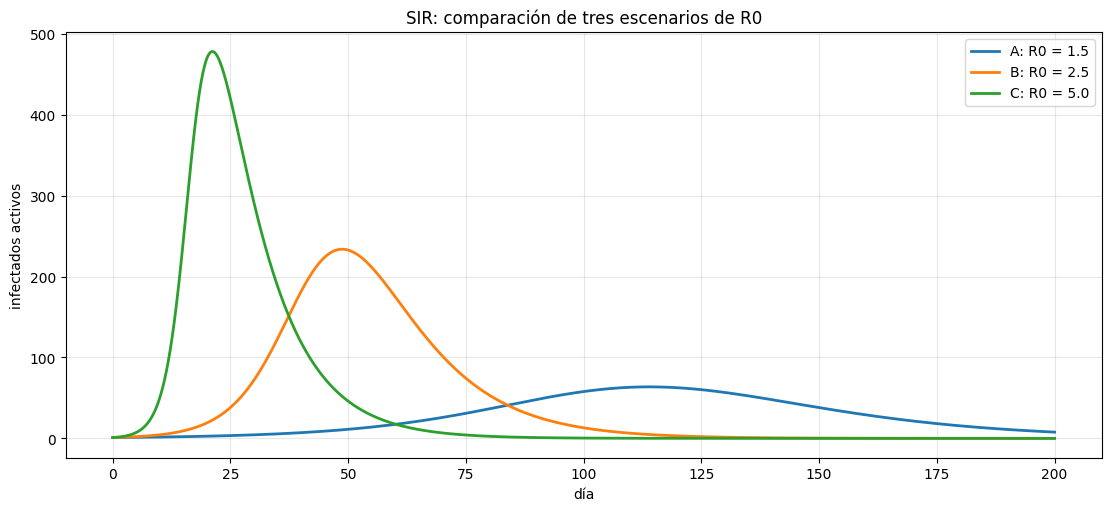

In [7]:
def sir(t, y, beta, gamma):
    S, I, R = y
    N = S + I + R
    dS = -beta * S * I / N
    dI = beta * S * I / N - gamma * I
    dR = gamma * I
    return [dS, dI, dR]

# Condiciones iniciales
N = 1000
I0 = 1
S0 = N - I0
gamma = 0.1           # 10 días para recuperarse

# Tres escenarios variando beta
escenarios = {
    'A: R0 = 1.5': 0.15,
    'B: R0 = 2.5': 0.25,
    'C: R0 = 5.0': 0.50,
}

resultados = {}
fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
for etiqueta, beta in escenarios.items():
    sol = solve_ivp(sir, (0, 200), [S0, I0, 0], args=(beta, gamma),
                    t_eval=np.linspace(0, 200, 1000), rtol=1e-8)
    ax.plot(sol.t, sol.y[1], label=etiqueta, lw=2)
    pico = sol.t[np.argmax(sol.y[1])]
    total = N - sol.y[0][-1]
    resultados[etiqueta] = (sol, pico, total)
    print(f"{etiqueta} -> pico en día {pico:.0f}, "
          f"infectados totales: {total:.0f} ({100*total/N:.1f} %)")

ax.set_xlabel('día'); ax.set_ylabel('infectados activos')
ax.set_title('SIR: comparación de tres escenarios de R0')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [8]:
# Altura del pico y duración del brote (último día con al menos 1 infectado activo)
print(f"{'escenario':14s} {'día del pico':>12s} {'I máx':>8s} {'% infectado':>12s} {'duración (I ≥ 1)':>17s}")
for etiqueta, (sol, pico, total) in resultados.items():
    I = sol.y[1]
    duracion = sol.t[np.where(I >= 1)[0][-1]]
    print(f"{etiqueta:14s} {pico:12.0f} {I.max():8.0f} {100*total/N:11.1f}% {duracion:17.0f}")

escenario      día del pico    I máx  % infectado  duración (I ≥ 1)
A: R0 = 1.5             114       64        57.0%               200
B: R0 = 2.5              49      234        89.3%               135
C: R0 = 5.0              21      478        99.3%                90


**Resultados** (con $N=1000$, $I_0=1$, $\gamma=0.1$):

| Escenario | $R_0$ | Día del pico | Infectados en el pico | Fracción total infectada |
|---|---|---|---|---|
| A (influenza estacional) | 1.5 | ~114 | ~64 | ~57 % |
| B (SARS-CoV-2 original) | 2.5 | ~49 | ~234 | ~89 % |
| C (sarampión sin vacunación) | 5.0 | ~21 | ~478 | ~99 % |

Al subir $R_0$ el pico llega **mucho antes**, es **mucho más alto** y la fracción de infectados al final crece (con $S_0\approx N$, la fracción final $z$ cumple $z=1-e^{-R_0 z}$). La epidemia también es más corta: cuanto más contagiosa, más rápido se agota la población susceptible. En el escenario A la última columna llega a 200 porque a los 200 días todavía quedan infectados activos (la ventana de simulación se queda corta para ese caso).

### Pregunta clave: ¿es realista el escenario C?

No del todo. El modelo asume una población **totalmente susceptible**, **homogénea** y que se mezcla al azar, sin intervenciones. En la realidad el sarampión se enfrenta con **vacunación**: si una fracción $p$ de la población es inmune, el número efectivo es $R_{\text{ef}}=R_0(1-p)$, y la epidemia no despega cuando $R_{\text{ef}}<1$, es decir, cuando

$$p>1-\frac{1}{R_0}.$$

Para $R_0=5$ el umbral de **inmunidad colectiva** es $1-1/5=80\,\%$ (en el sarampión real, con $R_0$ de 12 a 18, sube al 92–95 %). Abajo se verifica con el mismo modelo, empezando con una fracción $p$ de recuperados/vacunados. Al modelo también le faltan: período de latencia (SEIR), cambios de conducta, cuarentenas, heterogeneidad por edad o contactos y estocasticidad cuando hay pocos casos.

umbral de inmunidad colectiva 1 - 1/R0 = 80%
cobertura   0%: I máx =  478.3, infectados totales =  993.0
cobertura  50%: I máx =  117.1, infectados totales =  446.5
cobertura  70%: I máx =   19.6, infectados totales =  175.9
cobertura  80%: I máx =    1.0, infectados totales =   17.7
cobertura  85%: I máx =    1.0, infectados totales =    3.8


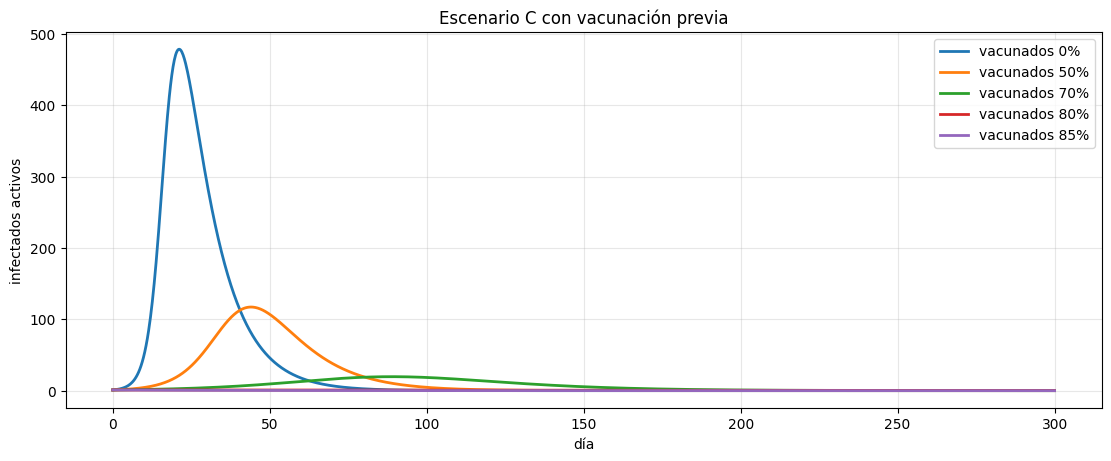

In [9]:
# Escenario C (beta = 0.5, R0 = 5) con distintas coberturas de vacunación p
beta_c = 0.50
umbral = 1 - 1 / 5.0
fig, ax = plt.subplots(figsize=(11, 4.5), layout='constrained')
print(f"umbral de inmunidad colectiva 1 - 1/R0 = {umbral:.0%}")
for p in [0, 0.5, 0.7, 0.8, 0.85]:
    S0v = N * (1 - p) - I0
    sol = solve_ivp(sir, (0, 300), [S0v, I0, N * p], args=(beta_c, gamma),
                    t_eval=np.linspace(0, 300, 1500), rtol=1e-8)
    nuevos = (S0v + I0) - sol.y[0][-1]               # infectados a lo largo del brote
    ax.plot(sol.t, sol.y[1], lw=2, label=f"vacunados {p:.0%}")
    print(f"cobertura {p:4.0%}: I máx = {sol.y[1].max():6.1f}, infectados totales = {nuevos:6.1f}")
ax.set_xlabel('día'); ax.set_ylabel('infectados activos')
ax.set_title('Escenario C con vacunación previa'); ax.legend(); ax.grid(alpha=0.3)
plt.show()

Con 0–70 % de cobertura todavía hay brote (cada vez más pequeño); con **80 % o más** el máximo de infectados es 1 (el caso inicial: $I$ solo decrece) y prácticamente no hay brote, tal como predice $1-1/R_0$.

---
## Parte 4: Ajuste del logístico a la población de Costa Rica

In [10]:
# Datos históricos del INEC: años censales + estimación 2025
anios = np.array([1864, 1892, 1927, 1950, 1973,
                  1984, 2000, 2011, 2022, 2025])
poblacion = np.array([120000, 243000, 472000, 800000, 1872000,
                      2417000, 3810000, 4301000, 5044197, 5191716])

# Trabajamos con t = anios - 1864 para que el tiempo empiece en 0
t = anios - anios[0]

# Modelo logístico (solución analítica)
def logistico_analitico(t, K, r, N0):
    return K / (1 + ((K - N0) / N0) * np.exp(-r * t))

# Ajuste de parámetros
params, cov = curve_fit(logistico_analitico, t, poblacion,
                        p0=[6e6, 0.03, 120000])
K_hat, r_hat, N0_hat = params
err = np.sqrt(np.diag(cov))                    # error estándar de cada parámetro

print(f"Capacidad de carga estimada K = {K_hat/1e6:.2f} millones (± {err[0]/1e6:.2f})")
print(f"Tasa de crecimiento r = {r_hat:.4f} por año (± {err[1]:.4f})")
print(f"Población inicial implícita = {N0_hat:.0f} (± {err[2]:.0f})")

Capacidad de carga estimada K = 6.95 millones (± 0.58)
Tasa de crecimiento r = 0.0403 por año (± 0.0037)
Población inicial implícita = 31537 (± 12304)


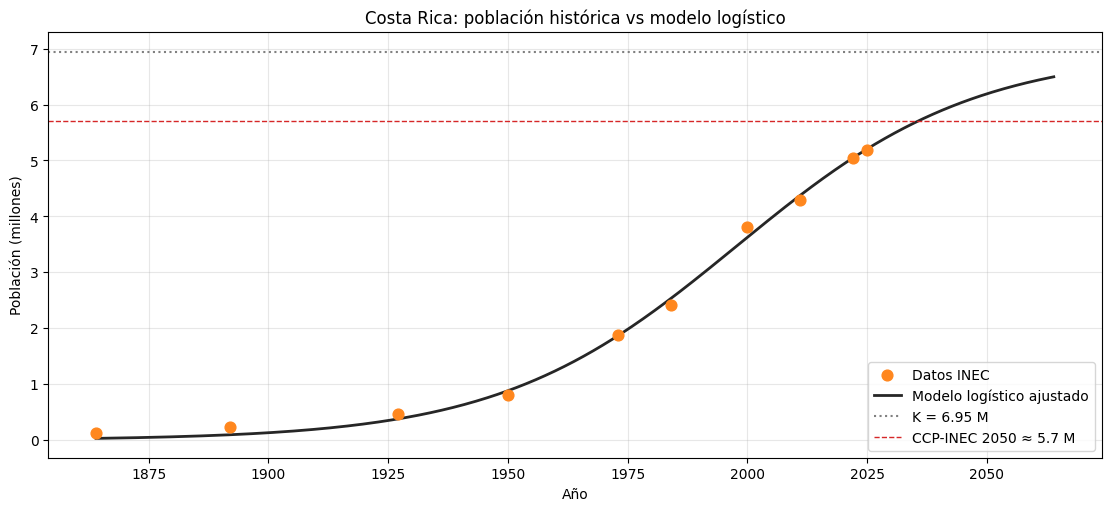

residuos (miles): [  88.  147.   93.  -83.    4. -113.  185.  -72.    2.  -13.]
RMSE = 99 mil habitantes
r entre 1864 y 2022 (exponencial): 0.0237
r entre 1950 y 2022 (exponencial): 0.0256
r entre 1973 y 2022 (exponencial): 0.0202


In [11]:
# Visualización del ajuste
t_smooth = np.linspace(0, 200, 500)
fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
ax.scatter(anios, poblacion/1e6, color='#FF871E', s=60, zorder=3, label='Datos INEC')
ax.plot(anios[0] + t_smooth, logistico_analitico(t_smooth, *params)/1e6,
        color='#262626', lw=2, label='Modelo logístico ajustado')
ax.axhline(K_hat/1e6, color='gray', linestyle=':', label=f'K = {K_hat/1e6:.2f} M')
ax.axhline(5.7, color='tab:red', linestyle='--', lw=1, label='CCP-INEC 2050 ≈ 5.7 M')
ax.set_xlabel('Año'); ax.set_ylabel('Población (millones)')
ax.set_title('Costa Rica: población histórica vs modelo logístico')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

res = poblacion - logistico_analitico(t, *params)
print("residuos (miles):", (res/1e3).round(0))
print(f"RMSE = {np.sqrt(np.mean(res**2))/1e3:.0f} mil habitantes")

# r "a mano" con dos censos, suponiendo crecimiento exponencial: r = ln(N2/N1)/(t2-t1)
for a, b in [(1864, 2022), (1950, 2022), (1973, 2022)]:
    ia, ib = list(anios).index(a), list(anios).index(b)
    print(f"r entre {a} y {b} (exponencial): {np.log(poblacion[ib]/poblacion[ia])/(b-a):.4f}")

**Resultados.** El ajuste da $\hat K\approx 6.95$ millones, $\hat r\approx 0.040$ por año y una población inicial implícita $\hat N_0\approx 31\,500$ (muy por debajo de los 120 000 observados en 1864).

**¿Por qué difiere $\hat r\approx0.040$ del $r\approx0.022$ estimado a mano con dos censos?**
- La estimación con dos censos supone **crecimiento exponencial puro**, $N=N_0e^{rt}$, y entonces $r$ es la tasa *neta promedio* observada, que ya incluye el efecto de frenado ($1-N/K$) durante todo el período. En el modelo logístico, $r$ es la tasa **intrínseca** (cuando $N\ll K$), que solo se observa al inicio; luego la tasa efectiva $r(1-N/K)$ va cayendo. Por eso $\hat r$ logístico es mayor que la tasa promedio de dos censos (que ronda 0.02–0.026 según los censos elegidos).
- El valor de $r$ depende de qué par de censos se use: el país creció más rápido a mediados del siglo XX y más lento después (transición demográfica), así que un solo par no representa toda la historia.
- El ajuste por mínimos cuadrados usa los 10 puntos a la vez, y $r$, $K$ y $N_0$ están correlacionados (los errores estándar son grandes, sobre todo el de $K$, ±0.6 M).

**Comparación con la proyección oficial.** El CCP-INEC proyecta ≈ 5.7 millones en 2050 y luego un descenso, mientras que el logístico da $K\approx 6.95$ M, mayor que el máximo proyectado, y una población que sigue creciendo hacia $K$. **No coinciden**, y la razón es que el logístico es demasiado simple para este fenómeno:
- Supone que el crecimiento se frena por la saturación de recursos, cuando en Costa Rica lo frena la **caída de la fecundidad** (transición demográfica), que no depende de $N/K$.
- Es **monótono**: converge a $K$ y no puede reproducir un pico seguido de descenso (envejecimiento, tasas de reemplazo por debajo de 2.1).
- Ignora la **migración** y la estructura por edades.
- Los datos solo cubren la fase de crecimiento; con pocos puntos cerca del límite, $K$ está mal identificado.

Un modelo con estructura por edades o con $r$ que depende del tiempo capturaría mejor el descenso.

---
## Parte 5: Reflexión grupal

**Observación matemática.** Al subir $R_0$ el brote se vuelve más **rápido, más alto y más corto**: el pico pasa del día ~114 ($R_0=1.5$) al día ~21 ($R_0=5$), y la fracción infectada de ~57 % a ~99 %. La duración del brote (hasta que queda menos de 1 infectado) baja de más de 200 días en A a ~135 días en B y ~90 días en C. Además, la cobertura de vacunación crítica $1-1/R_0$ crece con $R_0$ (33 %, 60 %, 80 %).

**Observación técnica.** `solve_ivp` es intuitivo cuando el campo vectorial se escribe como función `f(t, y)`, pero las dificultades típicas son: (1) el **orden de los argumentos** (`t` primero, luego `y`); (2) la forma de `sol.y`, que es una matriz *(variables × tiempos)*, por eso `sol.y[1]` son los infectados y no el instante 1; (3) pasar parámetros con `args=(...)` y recordar que `y0` debe ser una lista; (4) usar `t_eval` para obtener una malla fija de salida.

**Pregunta abierta.** ¿Cómo cambiaría la dinámica con un modelo SEIR o con vacunación y cambios de conducta dependientes del tiempo? ¿Podemos estimar $\beta$ y $\gamma$ a partir de datos reales de casos (dengue/COVID-19 en Costa Rica) y cuantificar la incertidumbre con inferencia bayesiana (PyMC, semana 4)? Para el proyecto: ¿qué modelo de crecimiento con saturación (logístico, Gompertz, Bass) ajusta mejor una serie de adopción o de población?